# 구내식당 점심 줄: OR-Tools로 최적 시차 배정을 찾고 SimPy로 검증하기

**누가 읽으면 좋은가:** 구내식당·매장·시설의 혼잡을 데이터로 줄이고 싶은 운영 담당자, 그리고 최적화(OR)와 시뮬레이션을 실무에 같이 쓰는 방법이 궁금한 분.

이 노트북은 데이터팝콘 [현업 시뮬레이션 진단](https://simulation.datapopcorn.ai/business/)의 재현 코드입니다. 순서는 이렇습니다.

1. 입장 태깅 기록으로 지금의 점심 몰림을 확인한다
2. SimPy 모델이 현장에서 잰 대기 시간을 재현하는지 검증한다
3. OR-Tools CP-SAT으로 "부서를 최소한만 옮기면서 몰림을 줄이는" 배정을 몰림 한도별로 구한다
4. 각 배정을 SimPy로 30번씩 돌려, 목표(평균 대기 3분, 오래 기다린 10%도 8분 이하)를 채우는 가장 적은 변경을 고른다
5. 웹 도구(highs-js + 자바스크립트 엔진)와 결과를 대조한다

> 데이터는 모두 **가상 고객사 A**(판교 IT 기업 본사를 가정, 점심 620명)의 **가상 데이터**입니다. 실제 기업 수치가 아닙니다.

왜 둘을 같이 쓰나: 최적화는 "가장 좋은 배정"을 찾지만 평균만 보고, 시뮬레이션은 몰리는 순간의 줄까지 보여 주지만 정해 준 안만 비교합니다. 그래서 최적화로 후보를 만들고 시뮬레이션으로 검증합니다.

## Step 1. 준비

In [1]:
!pip -q install ortools simpy
!apt-get -qq install -y fonts-nanum > /dev/null 2>&1 || true

In [2]:
import os, matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager as fm
for p in ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf", "/System/Library/Fonts/Supplemental/AppleGothic.ttf"]:
    if os.path.exists(p):
        fm.fontManager.addfont(p); matplotlib.rcParams["font.family"] = fm.FontProperties(fname=p).get_name(); break
matplotlib.rcParams["axes.unicode_minus"] = False
import urllib.request
BASE = "https://raw.githubusercontent.com/team-datapopcorn/datapopcorn-assets/main/simulation-cafeteria-or/"   # 같은 데이터가 웹 도구(simulation.datapopcorn.ai/fit/cafeteria/)에도 있습니다
for f in ["sample-company-a.csv", "sample-company-a-depts.csv"]:
    if not os.path.exists(f): urllib.request.urlretrieve(BASE + f, f)
print(open("sample-company-a-depts.csv", encoding="utf-8").read())

부서,인원,가장 이른 출발,가장 늦은 출발,검토 중인 안,메모
경영지원,40,11:30,12:20,12:00,
인사,25,11:30,12:20,12:00,
재무,30,11:30,12:20,12:00,
영업1팀,70,12:00,12:20,12:00,오전 외근 복귀 후 출발
영업2팀,60,12:00,12:20,12:00,오전 외근 복귀 후 출발
마케팅,55,11:30,12:20,12:00,
개발1팀,80,11:30,12:20,11:40,
개발2팀,75,11:30,12:20,11:40,
디자인,35,11:30,12:20,12:00,
데이터,45,11:30,12:20,12:00,
고객지원,60,11:30,11:40,11:40,13시 상담 피크 전 복귀
연구소,45,11:40,12:20,12:00,오전 실험 마무리



## Step 2. 모델 코드

아래 한 셀에 전부 들어 있습니다.
- `solve_plan`: OR-Tools CP-SAT. 부서마다 출발 시각(11:30~12:20, 10분 간격) 하나를 고르고, 가장 몰리는 시각의 인원을 T 이하로 두면서 **옮기는 사람·분(인원 × 12시와의 차이)**을 최소화합니다. 동점이면 웹 도구와 같은 답이 나오도록 작은 동점 해소 값을 더합니다.
- `apply_plan`: 실제 태깅 기록에서 11:50~12:15에 온 사람(부서 단위로 움직이는 사람)을 부서 인원 비율대로 나눠, 부서 출발 시각만큼 옮깁니다.
- `simulate`: SimPy 이산사건 시뮬레이션. 도착 → 가장 짧은 배식 줄 → 배식(삼각분포) → 자리(없으면 식판 들고 대기) → 식사 → 퇴장.

In [3]:
"""구내식당 점심: OR-Tools CP-SAT 최적 시차 배정 + SimPy 검증 (데이터팝콘 현업 시뮬레이션 진단 샘플)
가상 고객사 A의 가상 데이터. 기준 시각 11:30 = 0분, 12:00 = 30분."""
import math, random, statistics as st
import pandas as pd

START = 11 * 60 + 30
SLOTS = [0, 10, 20, 30, 40, 50]           # 11:30 ~ 12:20 출발 후보
PEAK_FROM, PEAK_TO, NOON = 20, 45, 30     # 11:50~12:15 사이 도착 = 부서 단위로 움직이는 사람

def hm(m): m = int(round(m)) + START; return f"{m // 60}:{m % 60:02d}"
def to_min(s): h, m = s.strip().split(":")[:2]; return int(h) * 60 + int(m) - START

def load_arrivals(path):
    df = pd.read_csv(path)
    t = pd.to_datetime(df.iloc[:, 0])
    a = (t.dt.hour * 60 + t.dt.minute + t.dt.second / 60 - START).tolist()
    return sorted(x for x in a if 0 <= x < 120)

def load_depts(path):
    d = pd.read_csv(path)
    return [dict(name=r["부서"], n=int(r["인원"]), lo=to_min(r["가장 이른 출발"]), hi=to_min(r["가장 늦은 출발"])) for _, r in d.iterrows()]

# ---------- 1. 최적 배정 (OR-Tools CP-SAT) ----------
def cost(d, i, s):
    """1000 × 사람·분(인원 × 12시와의 차이) + 동점 해소용 작은 값. 웹 도구(highs-js)와 같은 목적함수."""
    return 1000 * d["n"] * abs(s - NOON) + (i + 1) * (SLOTS.index(s) + 1)

def solve_plan(depts, T, time_limit=10):
    """가장 몰리는 출발 시각의 인원을 T 이하로 두면서 옮기는 사람·분을 최소화한다."""
    from ortools.sat.python import cp_model
    m = cp_model.CpModel()
    x = {(i, s): m.NewBoolVar(f"x_{i}_{s}") for i, d in enumerate(depts) for s in SLOTS if d["lo"] <= s <= d["hi"]}
    for i in range(len(depts)):
        m.AddExactlyOne(x[i, s] for s in SLOTS if (i, s) in x)
    for s in SLOTS:
        m.Add(sum(depts[i]["n"] * v for (i, t), v in x.items() if t == s) <= T)
    m.Minimize(sum(cost(depts[i], i, s) * v for (i, s), v in x.items()))
    sv = cp_model.CpSolver(); sv.parameters.max_time_in_seconds = time_limit
    r = sv.Solve(m)
    if r != cp_model.OPTIMAL: return None
    plan = [next(s for s in SLOTS if (i, s) in x and sv.Value(x[i, s])) for i in range(len(depts))]
    return dict(T=T, plan=plan, moved=moved_of(depts, plan), peak=peak_of(depts, plan))

def moved_of(depts, plan): return sum(d["n"] * abs(p - NOON) for d, p in zip(depts, plan))
def peak_of(depts, plan): return max(sum(d["n"] for d, p in zip(depts, plan) if p == s) for s in SLOTS)

def peak_grid(depts):
    """몰림 한도 후보: 이론 최저(전체/시각 수, 가장 큰 부서)부터 전체 인원까지 12단계 (웹 도구와 같음)"""
    tot = sum(d["n"] for d in depts); lb = max(math.ceil(tot / len(SLOTS)), max(d["n"] for d in depts))
    g = [lb] + [int(math.floor((lb + (tot - lb) * k / 11) / 5 + 0.5) * 5) for k in range(1, 12)]
    return sorted(set(g))

# ---------- 2. 배정을 실제 도착 기록에 적용 ----------
def apply_plan(arrivals, depts, plan):
    """11:50~12:15에 온 사람을 부서 인원 비율대로 (시간순, 가중 라운드로빈) 나누고 부서 출발 시각만큼 옮긴다.
    JS(/fit/fitlib.js applyPlan)와 같은 규칙이라 두 엔진이 같은 도착 기록을 쓴다."""
    tot = sum(d["n"] for d in depts); cur = [0.0] * len(depts); out = []
    for a in arrivals:
        if PEAK_FROM <= a < PEAK_TO:
            for i, d in enumerate(depts): cur[i] += d["n"] / tot
            k = max(range(len(depts)), key=lambda i: (cur[i], -i)); cur[k] -= 1
            out.append(min(118, max(0.1, a + plan[k] - NOON)))
        else: out.append(a)
    return sorted(out)

def shift_share(arrivals, frac=0.4, delta=-20, seed=7):
    r = random.Random(seed)
    return sorted(min(118, max(0.1, a + delta)) if PEAK_FROM <= a < PEAK_TO and r.random() < frac else a for a in arrivals)

# ---------- 3. SimPy 모델 ----------
def simulate(arrivals, lines=3, serve_sec=14, seats=216, eat_min=18, seed=1):
    import simpy
    rnd = random.Random(seed); env = simpy.Environment()
    L = [simpy.Resource(env, capacity=1) for _ in range(lines)]
    S = simpy.Resource(env, capacity=seats)
    s = serve_sec / 60; rec = []
    def person(a):
        yield env.timeout(a - env.now)
        order = list(range(lines)); rnd.shuffle(order)
        k = min(order, key=lambda j: len(L[j].queue) + L[j].count)
        with L[k].request() as rq:
            yield rq; q0 = env.now
            yield env.timeout(rnd.triangular(0.6 * s, 1.4 * s, s))
        yield env.timeout(0.4); ready = env.now
        rq = S.request(); yield rq; seat_t = env.now
        yield env.timeout(rnd.triangular(0.6 * eat_min, 1.4 * eat_min, eat_min) + 0.1)
        S.release(rq)
        rec.append((q0 - a, seat_t - ready))
    def src():
        for a in arrivals: env.process(person(a))
        yield env.timeout(0)
    env.process(src()); env.run()
    w = sorted(q + t for q, t in rec)
    return dict(avgWait=st.mean(w), avgQueueWait=st.mean(q for q, _ in rec), p90Wait=w[int(len(w) * 0.9)],
                stood=sum(t > 0.25 for _, t in rec))

def run_many(arrivals, n=30, **kw):
    rs = [simulate(arrivals, seed=i, **kw) for i in range(1, n + 1)]
    return {k: round(st.mean(r[k] for r in rs), 1) for k in rs[0]}

## Step 3. 지금의 점심 몰림

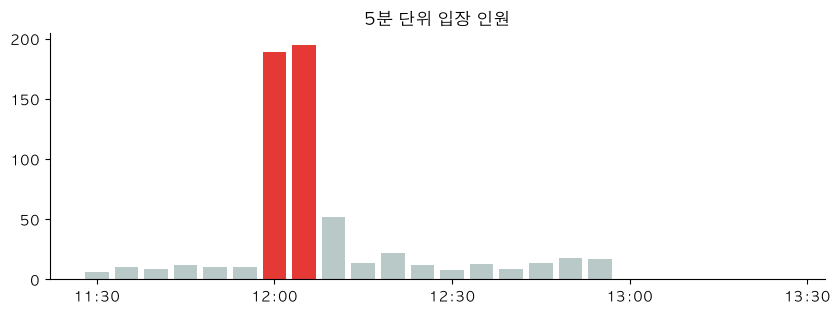

전체 620명, 12:00~12:10 입장 384명 (62%), 부서 단위로 움직이는 비율 73.5%


In [4]:
arr = load_arrivals("sample-company-a.csv"); depts = load_depts("sample-company-a-depts.csv")
share = sum(PEAK_FROM <= a < PEAK_TO for a in arr) / len(arr)
bins = [0] * 24
for a in arr: bins[int(a // 5)] += 1
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(24), bins, color=["#e53935" if i in (6, 7) else "#b8c9c8" for i in range(24)])
ax.set_xticks(range(0, 25, 6)); ax.set_xticklabels(["11:30", "12:00", "12:30", "13:00", "13:30"])
ax.set_title("5분 단위 입장 인원"); ax.spines[["top", "right"]].set_visible(False); plt.show()
print(f"전체 {len(arr)}명, 12:00~12:10 입장 {bins[6] + bins[7]}명 ({(bins[6] + bins[7]) / len(arr):.0%}), 부서 단위로 움직이는 비율 {share:.1%}")

## Step 4. 재현 검증: 현장 측정값과 맞추기

12:00~12:20에 줄 선 40명의 대기를 스톱워치로 잰 평균이 9.5분(가상 값)이라고 합시다. 1인 배식 시간을 바꿔 가며 SimPy 결과가 같은 값을 내는 지점을 찾습니다. 이 단계를 통과해야 뒤의 비교를 믿을 수 있습니다.

In [5]:
MEASURED = 9.5
BASE_KW = dict(lines=3, seats=216, eat_min=18)
curve = {s: run_many(arr, n=10, serve_sec=s, **BASE_KW)["avgQueueWait"] for s in range(10, 19)}
SERVE = min(curve, key=lambda s: abs(curve[s] - MEASURED))
print({s: v for s, v in curve.items()})
print(f"→ 1인 배식 {SERVE}초에서 시뮬레이션 {curve[SERVE]}분, 실측 {MEASURED}분 (차이 {abs(curve[SERVE] - MEASURED):.1f}분)")
KW = dict(BASE_KW, serve_sec=SERVE)

{10: 5.5, 11: 6.5, 12: 7.6, 13: 8.7, 14: 9.7, 15: 10.9, 16: 12.0, 17: 13.2, 18: 14.5}
→ 1인 배식 14초에서 시뮬레이션 9.7분, 실측 9.5분 (차이 0.2분)


## Step 5. 최적화 × 시뮬레이션: 몰림 한도별 최소 변경 배정

몰림 한도 T를 12단계로 바꿔 가며 CP-SAT으로 최소 변경 배정을 구하고, 각 배정을 SimPy로 30번 돌립니다. 몰림 한도만 낮추면 대기가 항상 줄 것 같지만, 실제로는 시각별 인원 분포에 따라 들쭉날쭉합니다. 그래서 시뮬레이션 검증이 필요합니다.

In [6]:
import pandas as pd
rows = []
for T in peak_grid(depts):
    sol = solve_plan(depts, T)
    if not sol: continue
    r = run_many(apply_plan(arr, depts, sol["plan"]), n=30, **KW)
    rows.append(dict(몰림한도=T, 옮긴사람분=sol["moved"], 평균대기=r["avgWait"], 오래기다린10퍼=r["p90Wait"], 자리기다린사람=r["stood"], plan=sol["plan"]))
front = pd.DataFrame(rows)
front = front[~front.plan.map(tuple).duplicated()].reset_index(drop=True)   # 같은 배정은 한 번만
front.drop(columns="plan")

,몰림한도,옮긴사람분,평균대기,오래기다린10퍼,자리기다린사람
0,150,6400,0.3,0.8,0.0
1,200,4800,2.1,4.6,229.9
2,245,4350,3.4,8.0,228.2
3,290,3900,4.6,11.1,232.7
4,340,3400,4.0,10.9,234.2
5,385,2950,3.7,10.7,236.9
6,430,2500,4.3,12.5,148.0
7,480,2000,5.6,15.0,174.8
8,525,1550,6.9,17.1,192.7
9,575,1200,8.0,18.8,221.7


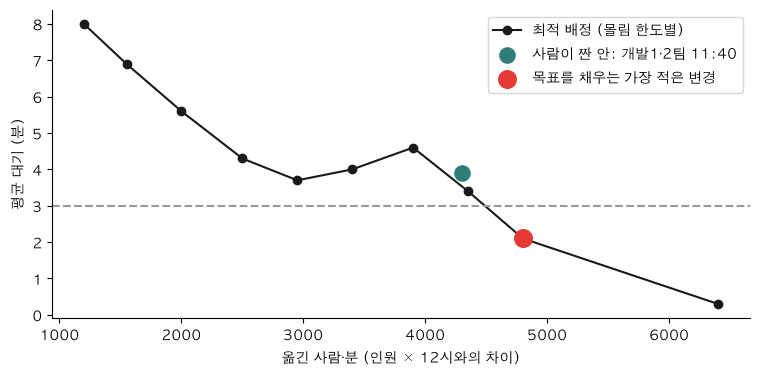

지금: {'avgWait': 10.4, 'avgQueueWait': 9.7, 'p90Wait': 21.8, 'stood': 273.4}
사람이 짠 안: 4300 {'avgWait': 3.9, 'avgQueueWait': 3.7, 'p90Wait': 10.0, 'stood': 96.6}
최적: {'몰림한도': 200, '옮긴사람분': 4800, '평균대기': 2.1, '오래기다린10퍼': 4.6, '자리기다린사람': 229.9}


,부서,인원,최적 출발,사람이 짠 안
0,경영지원,40,12:00,12:00
1,인사,25,12:00,12:00
2,재무,30,12:10,12:00
3,영업1팀,70,12:10,12:00
4,영업2팀,60,12:10,12:00
5,마케팅,55,12:00,12:00
6,개발1팀,80,12:00,11:40
7,개발2팀,75,11:50,11:40
8,디자인,35,11:50,12:00
9,데이터,45,11:50,12:00


In [7]:
TARGET_AVG, TARGET_P90 = 3.0, 8.0
ok = front[(front.평균대기 <= TARGET_AVG) & (front.오래기다린10퍼 <= TARGET_P90)]
best = ok.sort_values("옮긴사람분").iloc[0]
human_plan = [to_min(h) for h in pd.read_csv("sample-company-a-depts.csv")["검토 중인 안"]]   # 사람이 짠 안: 개발1·2팀 11:40
human = run_many(apply_plan(arr, depts, human_plan), n=30, **KW)
current = run_many(arr, n=30, **KW)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(front.옮긴사람분, front.평균대기, "o-", color="#1a1a1a", label="최적 배정 (몰림 한도별)")
ax.scatter([moved_of(depts, human_plan)], [human["avgWait"]], s=120, color="#2e7d7a", label="사람이 짠 안: 개발1·2팀 11:40", zorder=3)
ax.scatter([best.옮긴사람분], [best.평균대기], s=160, color="#e53935", label="목표를 채우는 가장 적은 변경", zorder=3)
ax.axhline(TARGET_AVG, ls="--", color="#999"); ax.set_xlabel("옮긴 사람·분 (인원 × 12시와의 차이)"); ax.set_ylabel("평균 대기 (분)")
ax.legend(); ax.spines[["top", "right"]].set_visible(False); plt.show()
print("지금:", current); print("사람이 짠 안:", moved_of(depts, human_plan), human); print("최적:", {k: (v.item() if hasattr(v, "item") else v) for k, v in best.drop(["plan"]).items()})
pd.DataFrame({"부서": [d["name"] for d in depts], "인원": [d["n"] for d in depts], "최적 출발": [hm(p) for p in best.plan], "사람이 짠 안": [hm(p) for p in human_plan]})

## Step 6. 웹 도구와 대조

[내 데이터로 돌려보기](https://simulation.datapopcorn.ai/fit/cafeteria/)는 같은 문제를 브라우저 안에서 HiGHS(highs-js)와 자바스크립트 시뮬레이션 엔진으로 풉니다. 아래는 웹 도구가 같은 데이터로 낸 값입니다. 배정은 12개 몰림 한도 모두 CP-SAT과 똑같았고, 대기 시간은 난수 흐름이 달라 소수점 차이가 납니다.

In [8]:
WEB = {"지금": 10.3, "사람이 짠 안": 3.8, "최적 배정": 2.1}
cmp = pd.DataFrame({"SimPy (이 노트북)": {"지금": current["avgWait"], "사람이 짠 안": human["avgWait"], "최적 배정": best.평균대기},
                    "웹 도구 (JS 엔진)": WEB})
cmp

,SimPy (이 노트북),웹 도구 (JS 엔진)
지금,10.4,10.3
사람이 짠 안,3.9,3.8
최적 배정,2.1,2.1


## Step 7. 한계

- 데이터는 모두 가상입니다. 실제 진단에서는 고객사의 태깅 기록과 현장 측정으로 같은 과정을 거칩니다.
- 부서 단위로 움직이는 사람은 11:50~12:15에 온 사람으로 정했습니다. 실제 부서 정보가 태깅 기록에 있으면 그것을 씁니다.
- 메뉴별 인기, 동선, 단체 입장은 모델에 없습니다.
- 배정 효과는 부서가 실제로 시각을 지킨다는 가정입니다. 2주 시범 운영 후 기록으로 전후를 비교해야 합니다.

데이터팝콘 · contact@datapopcorn.ai · https://simulation.datapopcorn.ai/business/